# siann quickstart

siann is nearest-neighbor search that decides how to search. Ask for exact neighbors or a recall target, and
it picks the method (exact search, an IVF or a graph) and, for each batch size, the device (the CPU, or the
Apple GPU), from measurements on your data and machine; `index.plan` says why.

The sections:

1. Setup: the metrics, and the data
2. Exact search
3. Approximate search: a recall target
4. Graphs
5. Where searches run: the CPU or the GPU, by batch size
6. Changing an index
7. Saving and loading
8. More options

Every number here is from the machine that ran this notebook; [BENCHMARKS](https://github.com/vglazer/siann/blob/main/BENCHMARKS.md) has
measurements on real datasets.

In [1]:
import time

import siann  # before NumPy: on Linux and Windows siann sets NumPy's BLAS up first

import matplotlib.pyplot as plt
import numpy as np

NAMES = {"l2": "L2", "l1": "L1", "linf": "L-infinity", "cosine": "cosine", "ip": "inner product"}
siann.__version__

'0.4.0'

## 1. Setup

**The metrics.** siann searches by five measures of nearness. Below, in two dimensions: 600 points, one
query (orange) and each metric's 25 nearest points to it (blue), inside the boundary that encloses them.

- [**L2**](https://en.wikipedia.org/wiki/Euclidean_distance) (Euclidean): straight-line distance, a circle. The usual choice for
  coordinates that are comparable measurements.
- [**L1**](https://en.wikipedia.org/wiki/Taxicab_geometry) (Manhattan): the sum of the coordinate differences, a diamond; less swayed
  by one outlying coordinate than L2.
- [**L-infinity**](https://en.wikipedia.org/wiki/Chebyshev_distance) (Chebyshev): the largest coordinate difference, a square; a
  worst-case bound on every coordinate.
- [**Cosine**](https://en.wikipedia.org/wiki/Cosine_similarity): direction only, a wedge from the origin. The usual choice for text
  and image embeddings.
- [**Inner product**](https://en.wikipedia.org/wiki/Dot_product): direction *and* length, everything beyond a line; for embeddings
  trained to be compared this way.

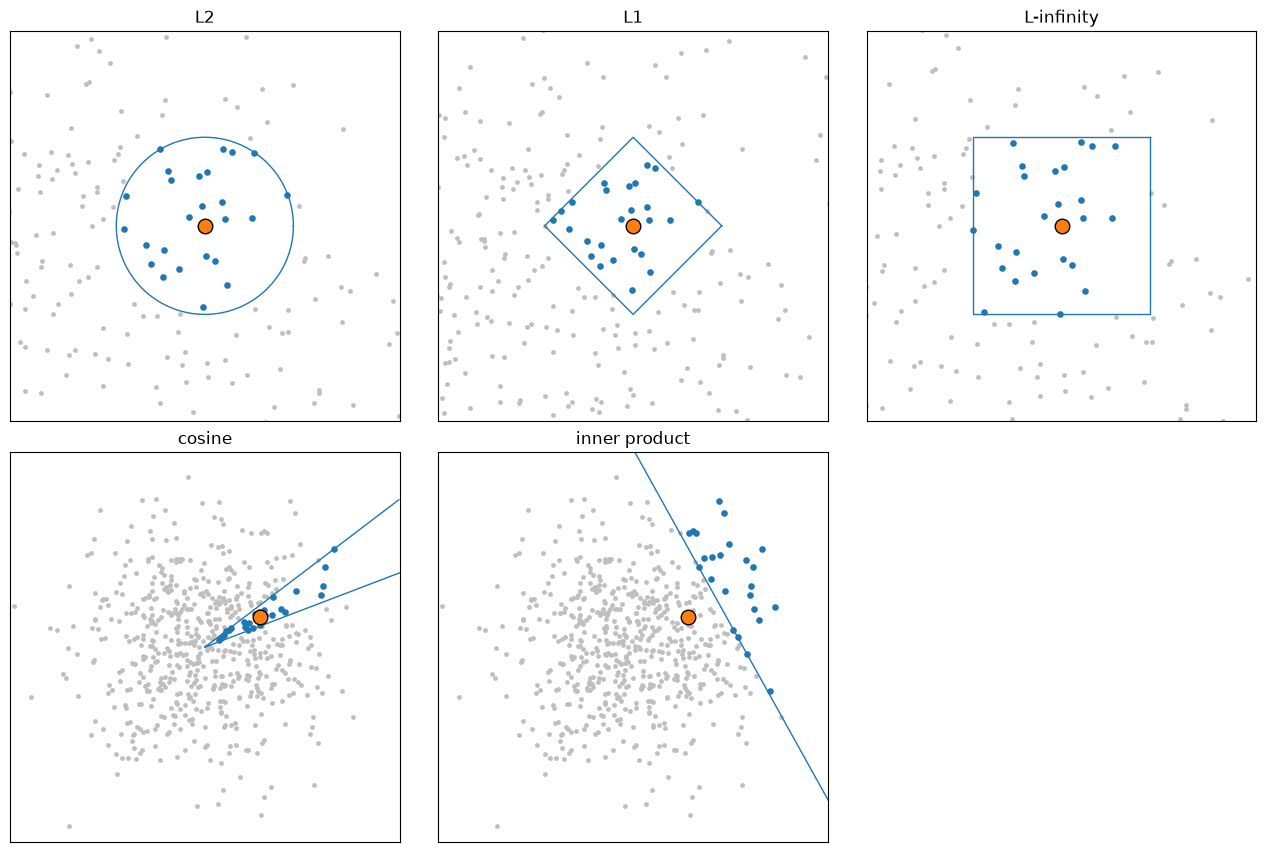

In [2]:
rng = np.random.default_rng(1)
pts = rng.standard_normal((600, 2), dtype=np.float32)
q = np.array([[0.9, 0.5]], dtype=np.float32)

fig, axes = plt.subplots(2, 3, figsize=(13, 8.6))
axes = axes.ravel()
axes[-1].axis("off")
for ax, metric in zip(axes, siann.METRICS):
    res = siann.Index(pts, metric, device="cpu").search(q, 25)
    near, kth = res.indices[0], res.scores[0, -1]
    ax.scatter(*pts.T, s=6, c="0.75")
    ax.scatter(*pts[near].T, s=14, c="tab:blue")
    ax.scatter(*q.T, s=110, c="tab:orange", edgecolors="black", linewidths=1, zorder=3)
    t = np.linspace(0, 2 * np.pi, 400)
    if metric == "l2":
        ax.plot(q[0, 0] + kth * np.cos(t), q[0, 1] + kth * np.sin(t), c="tab:blue", lw=1)
    elif metric == "l1":
        ax.plot(q[0, 0] + kth * np.array([1, 0, -1, 0, 1]), q[0, 1] + kth * np.array([0, 1, 0, -1, 0]), c="tab:blue", lw=1)
    elif metric == "linf":
        ax.plot(q[0, 0] + kth * np.array([1, -1, -1, 1, 1]), q[0, 1] + kth * np.array([1, 1, -1, -1, 1]), c="tab:blue", lw=1)
    elif metric == "cosine":
        a, w = np.arctan2(q[0, 1], q[0, 0]), np.arccos(np.clip(kth, -1, 1))
        for b in (a - w, a + w):
            ax.plot([0, 4 * np.cos(b)], [0, 4 * np.sin(b)], c="tab:blue", lw=1)
    else:   # the line q.x = kth, perpendicular to q
        u = q[0] / np.linalg.norm(q[0])
        base, along = u * kth / np.linalg.norm(q[0]), np.array([-u[1], u[0]])
        ax.plot(*np.array([base - 5 * along, base + 5 * along]).T, c="tab:blue", lw=1)
    ax.set_title(NAMES[metric])
    # the balls are small: zoom on the query; cosine and inner product regions run out from the origin
    span = 2.2 * kth if metric in ("l2", "l1", "linf") else 3.2
    cx, cy = (q[0] if metric in ("l2", "l1", "linf") else (0, 0))
    ax.set_xlim(cx - span, cx + span); ax.set_ylim(cy - span, cy + span)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
fig.tight_layout()

**The data.** Real embeddings cluster, so the rest of the notebook uses 200,000 vectors in 128 dimensions
drawn around 1,000 random centers, and 10,000 queries drawn the same way.

In [3]:
centers = rng.standard_normal((1000, 128), dtype=np.float32)


def sample(n):
    return (centers[rng.integers(0, len(centers), n)]
            + 0.3 * rng.standard_normal((n, 128), dtype=np.float32))


xb, xq = sample(200_000), sample(10_000)
xb.shape, xq.shape

((200000, 128), (10000, 128))

## 2. Exact search

`siann.Index(xb, metric)` builds an index; `index.search(xq, k)` returns each query's `k` nearest, best
first, as `indices` (int64) and `scores`. Without a recall target the search is exact. `index.plan` says
what siann chose and why.

In [4]:
index = siann.Index(xb, metric="cosine")
res = index.search(xq[:1000], k=5)
print(res.indices[:2], res.scores[:2], sep="\n")
print(index.plan)

[[141620  32881  99292  30736 181940]
 [165465 119464 126810 167009 169820]]
[[0.94919854 0.9488592  0.94846785 0.94697994 0.9468435 ]
 [0.9333264  0.93145066 0.9305314  0.9304897  0.9302278 ]]
siann.Index: 200,000 vectors, 128 dimensions, metric cosine
  kind: exact
  device: auto
  exact search (no recall target): the results are the true nearest neighbors
  GPU found: always on the GPU (profile: siann's default, tuned on an Apple M3 Max with about a million vectors)
  on the CPU: a BLAS matrix multiply through NumPy and siann's Rust top-k
  GPU backend: MLX
  memory: 98 MB of vectors, copied to the GPU when a search first needs them; each GPU call works within 4.0 GB (the GPU can use 48.0 GB)
  cosine: vectors normalized to unit length and ranked by inner product


**Scores** are each metric's natural value: the distance for L2 (not squared), L1 and L-infinity, smallest
first; the similarity for cosine and inner product, largest first. Below they are checked against NumPy.

**Ground truth.** Approximate search is judged by its *recall*: the share of the true nearest neighbors it
finds. Exact search gives those true neighbors, here the 10 nearest of all 10,000 queries.

In [5]:
exact = siann.Index(xb, "l2")
exact.search(xq, 10)                                   # the first call copies the vectors, compiles kernels
start = time.perf_counter()
res = exact.search(xq, 10)
truth = res.indices
print(f"true 10 nearest of {len(xq):,} queries among {len(xb):,}: {time.perf_counter() - start:.2f} s")
print("scores exact:", np.allclose(res.scores[:100], np.linalg.norm(xb[truth[:100]] - xq[:100, None], axis=2), rtol=1e-4))


def recall(found, truth):
    return np.mean([len(set(a) & set(b)) / truth.shape[1] for a, b in zip(found, truth)])

true 10 nearest of 10,000 queries among 200,000: 0.12 s
scores exact: True


## 3. Approximate search

Approximate search compares each query with only some of the vectors, trading a little recall for a lot of
speed. siann has two methods for it; this section uses the first.

**The IVF** ([inverted file](https://en.wikipedia.org/wiki/Inverted_index)) groups the vectors into *lists* by
[k-means](https://en.wikipedia.org/wiki/K-means_clustering), one per cluster center (*centroid*). A search scans only the lists whose
centroids are nearest the query: *nprobe* of them. More lists find more true neighbors and take longer.

**A recall target** (`recall=0.95`: 95 of every 100 true neighbors found, on average) sets nprobe: siann
picks the smallest nprobe that reaches the target on a sample of queries (*calibration*). Here the sample is
1,000 of the queries (`calibration_queries=`); the target then holds on the other 9,000.

In [6]:
approx = siann.Index(xb, "l2", recall=0.95, calibration_queries=xq[:1000])
rest, rest_truth = xq[1000:], truth[1000:]
print(approx.plan)
print(f"recall@10 on the other {len(rest):,} queries: {recall(approx.search(rest, 10).indices, rest_truth):.3f}")

siann.Index: 200,000 vectors, 128 dimensions, metric l2
  kind: ivf
  device: auto
  approximate search: an IVF of 1,789 lists (about 4 sqrt(n)), built in 0.5 s (siann's k-means, 10 iterations)
  lists stored as float16 on the GPU (recall moves by at most about 0.001) and float32 on the CPU
  calibrated: nprobe 2 reaches recall@10 0.958 (target 0.95) on 1,000 of the given calibration queries
  IVF chosen: 1.9 ms for 1,000 calibration queries on the GPU, against 12.5 ms for exact search
  no graph index: its widest search reached recall@10 0.282, below the target
  routing measured in 2.1 s: queries per search 1: the CPU, query-major (coarse step through BLAS); 2-255: the CPU, query-major; 256 and up: the GPU, query-major
  GPU found: approximate searches routed as above
  GPU backend: MLX
  memory: 98 MB of vectors, copied to the GPU when a search first needs them; each GPU call works within 4.0 GB (the GPU can use 48.0 GB)
recall@10 on the other 9,000 queries: 0.961


Approximate search pays most where exact search costs most: in large batches. Queries per second at each
batch size:

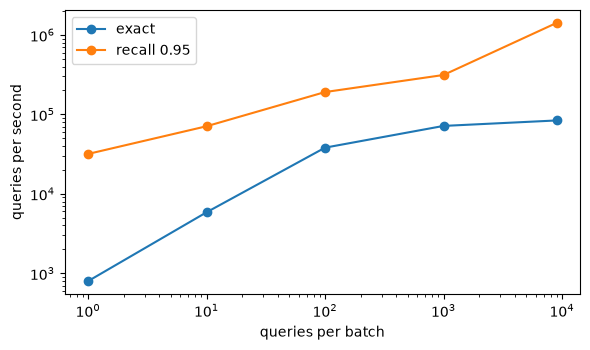

In [7]:
def rate(fn, b):
    fn(rest[:b])                                       # warm-up: copies, kernels for this shape
    calls = max(1, 2000 // b) if b < 1000 else 3
    start = time.perf_counter()
    for c in range(calls):
        fn(rest[c * b:(c + 1) * b] if b < 1000 else rest[:b])
    return calls * b / (time.perf_counter() - start)


sizes = [1, 10, 100, 1000, 9000]
exact_rate = [rate(lambda q: exact.search(q, 10), b) for b in sizes]
approx_rate = [rate(lambda q: approx.search(q, 10), b) for b in sizes]
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot(sizes, exact_rate, marker="o", label="exact")
ax.plot(sizes, approx_rate, marker="o", label="recall 0.95")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("queries per batch"); ax.set_ylabel("queries per second"); ax.legend()
fig.tight_layout()

**The trade-off.** `search(..., nprobe=)` overrides the calibrated nprobe for one search. Below, recall
against speed for 9,000 queries as nprobe doubles from 1 to 128: recall climbs towards 1 and speed falls
towards exact search's (red). The calibrated nprobe, ringed, is the fewest lists that reach the target.

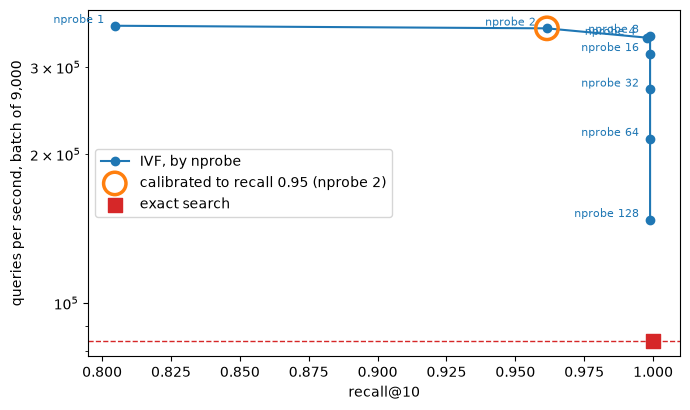

In [8]:
curve = []
for p in (1, 2, 4, 8, 16, 32, 64, 128):
    approx.search(rest, 10, nprobe=p)
    start = time.perf_counter()
    found = approx.search(rest, 10, nprobe=p).indices
    curve.append((recall(found, rest_truth), len(rest) / (time.perf_counter() - start), p))
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot([r for r, _, _ in curve], [s for _, s, _ in curve], marker="o", c="tab:blue", label="IVF, by nprobe")
for r, s, p in curve:
    ax.annotate(f"nprobe {p}", (r, s), textcoords="offset points", xytext=(-8, 2), ha="right", fontsize=8,
                color="tab:blue")
calibrated = [c for c in curve if c[2] == approx.nprobe]
if calibrated:
    ax.scatter([calibrated[0][0]], [calibrated[0][1]], s=260, facecolors="none", edgecolors="tab:orange",
               linewidths=2.5, zorder=3, label=f"calibrated to recall 0.95 (nprobe {approx.nprobe})")
ax.axhline(exact_rate[-1], color="tab:red", linestyle="--", linewidth=1)
ax.scatter([1.0], [exact_rate[-1]], marker="s", s=90, c="tab:red", zorder=3, label="exact search")
ax.set_yscale("log"); ax.set_xlabel("recall@10"); ax.set_ylabel("queries per second, batch of 9,000")
ax.legend(loc="center left"); fig.tight_layout()

**Which queries to calibrate on.** Without `calibration_queries=`, siann calibrates on 1,000 of the index's
own vectors, and the target holds for queries like them. Real queries often differ: on SIFT1M, calibrating on
its own vectors misses the target, and on Music-100 it scans five times the lists needed. Pass a sample of
real queries, or call `index.calibrate(queries)` later
([TUNING](https://github.com/vglazer/siann/blob/main/TUNING.md#calibration-meeting-the-recall-target-on-your-queries)).

## 4. Graphs

**A graph index** links each vector to some of its near neighbors (here 32) and searches by walking the
links from a few entry vectors: a query touches far fewer vectors than an IVF scans. siann's graphs are
CAGRA graphs, and siann builds them itself on any machine, for every metric. With a recall target, siann
builds a graph alongside the IVF, calibrates its search width to the target, and uses it for the batch sizes
where it is faster.

A graph fails on data made of tight clusters far apart, like this notebook's: each cluster links only to
itself, and a search reaches only the clusters it starts in. siann measures that when it builds the graph,
and the index above declined it; its plan says why:

In [9]:
print("\n".join(line.strip() for line in str(approx.plan).splitlines() if "graph" in line))

no graph index: its widest search reached recall@10 0.282, below the target


On data without such gaps a graph serves well. Below, an L1 index over 100,000 Gaussian vectors in 16
dimensions: `kind="graph"` sends every batch through the graph, and `nprobe=` sends one search through the
IVF instead, here on batches of 100.

In [10]:
g_xb = rng.standard_normal((100_000, 16), dtype=np.float32)
g_xq = rng.standard_normal((2_000, 16), dtype=np.float32)
l1 = siann.Index(g_xb, "l1", recall=0.95, calibration_queries=g_xq[:1000], kind="graph")
g_rest = g_xq[1000:]
l1_truth = siann.Index(g_xb, "l1").search(g_rest, 10).indices


def rate_on(fn, q, b=100):
    fn(q[:b])
    start = time.perf_counter()
    for s in range(0, len(q), b):
        fn(q[s:s + b])
    return len(q) / (time.perf_counter() - start)


print(f"graph: recall@10 {recall(l1.search(g_rest, 10).indices, l1_truth):.3f}, "
      f"{rate_on(lambda q: l1.search(q, 10), g_rest):,.0f} queries per second")
print(f"IVF (nprobe {l1.nprobe}): recall@10 {recall(l1.search(g_rest, 10, nprobe=l1.nprobe).indices, l1_truth):.3f}, "
      f"{rate_on(lambda q: l1.search(q, 10, nprobe=l1.nprobe), g_rest):,.0f} queries per second")

graph: recall@10 0.950, 202,723 queries per second
IVF (nprobe 121): recall@10 0.950, 202,672 queries per second


Both meet the target. Random vectors give neither method structure to exploit, so they run at about the same
speed; on real data the graph pulls ahead: by L1 on SIFT1M, 6.2 times the IVF at recall 0.95
([BENCHMARKS](https://github.com/vglazer/siann/blob/main/BENCHMARKS.md#graphs-for-l1-and-l-infinity)). The two find different neighbors, each
calibrated to the target on its own, so results can depend on the batch size's route; the plan says so.

[mlxvs](https://github.com/mikepapadim/mlxvs) is optional: installed (`pip install siann[graph]`, Apple
silicon), it builds L2, cosine and inner-product graphs faster on the GPU and searches GPU batches through
them.

## 5. Where searches run: the CPU or the GPU, by batch size

A GPU call has a fixed cost that a large batch spreads thin, so the CPU wins small batches and the GPU large
ones; where they cross depends on the metric, the method, the data and the machine. When an index is built,
siann times every path (each method on each device) at batch sizes from 1 to 4,096, and each search takes the
fastest for its size. The plan's routing line gives the result:

In [11]:
print(next(line.strip() for line in str(approx.plan).splitlines() if line.lstrip().startswith("routing")))

routing measured in 2.1 s: queries per search 1: the CPU, query-major (coarse step through BLAS); 2-255: the CPU, query-major; 256 and up: the GPU, query-major


`device="cpu"` or `device="gpu"` overrides it, for an index or for one search; both return the same
neighbors. Below, exact search on each device by batch size, for every metric. L1 and L-infinity have no
matrix-multiply form, so the GPU's lead is largest there.

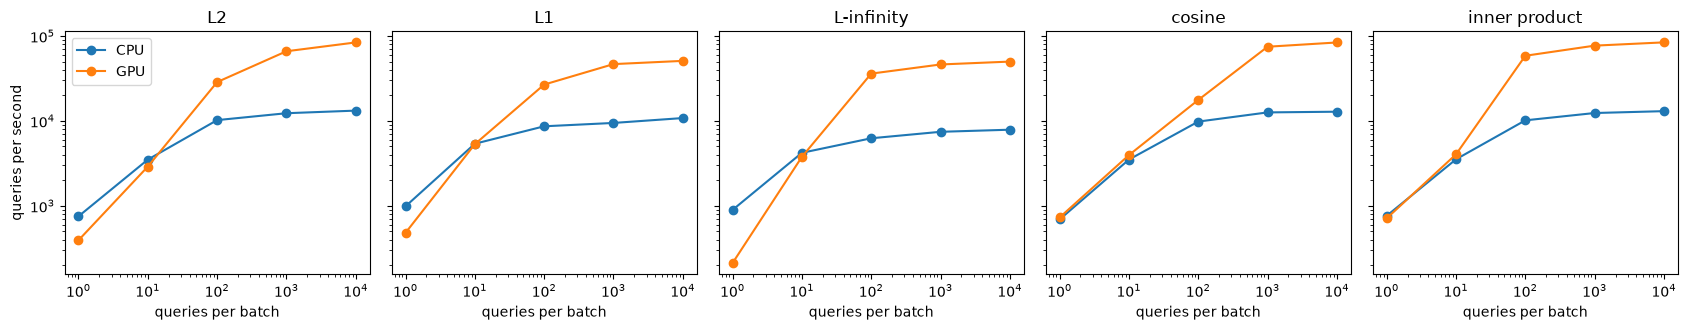

In [12]:
devices = ["cpu", "gpu"] if siann.gpu_available() else ["cpu"]
batches = [1, 10, 100, 1000, 10_000]
speed = {}
for metric in siann.METRICS:
    idx = siann.Index(xb, metric)
    for device in devices:
        for b in batches:
            idx.search(xq[:b], 10, device=device)      # the first call copies the vectors, compiles kernels
            start = time.perf_counter()
            idx.search(xq[:b], 10, device=device)
            speed[metric, device, b] = b / (time.perf_counter() - start)

fig, axes = plt.subplots(1, 5, figsize=(17, 3.4), sharey=True)
for ax, metric in zip(axes, siann.METRICS):
    for device in devices:
        ax.plot(batches, [speed[metric, device, b] for b in batches], marker="o", label=device.upper())
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("queries per batch"); ax.set_title(NAMES[metric])
axes[0].set_ylabel("queries per second"); axes[0].legend()
fig.tight_layout()

**Exact search's routing** comes from a *profile*: a threshold batch size per metric, above which a search
goes to the GPU. The default profile was tuned on an Apple M3 Max with about a million vectors;
`siann.tune` measures your own vectors on your machine (here two metrics, about half a minute). A profile
applies only where you pass it: `profile=` for one index, `siann.use_profile(profile)` for the process;
`profile.save(path)` and `siann.Profile.load(path)` keep it. `index.route(batch)` says where a batch goes.

In [13]:
profile = siann.tune(xb, metrics=("l2", "cosine"), budget=30)
print(siann.DEFAULT_PROFILE, profile, sep="\n")
tuned = siann.Index(xb, "l2", profile=profile)
{b: tuned.route(b) for b in (1, 8, 64, 1000)}

siann.Profile (siann's default, tuned on an Apple M3 Max with about a million vectors)
  l2      exact search on the CPU below 2 queries per batch, on the GPU from 2
  l1      exact search always on the GPU
  linf    exact search always on the GPU
  cosine  exact search always on the GPU
  ip      exact search always on the GPU
  approximate search (IVF): measured by each index when it is built
siann.Profile (tuned on 200,000 x 128 vectors, k = 10, 2026-11-28)
  l2      exact search on the CPU below 2 queries per batch, on the GPU from 2
  cosine  exact search always on the GPU
  approximate search (IVF): measured by each index when it is built
  queries per second, CPU / GPU, by batch size:
                          1               2               4               8              16              32              64             128             256             512           1,024
    l2            755 / 401       513 / 596   1,721 / 1,880   3,061 / 3,668   5,212 / 9,317  7,910 / 17,177  8,

{1: 'cpu', 8: 'gpu', 64: 'gpu', 1000: 'gpu'}

## 6. Changing an index

`index.add(x)` adds vectors and returns their ids (row numbers, unless `add(x, ids=...)` names them).
Added vectors are searched exactly until 10,000 of them (or 1% of the index) have gathered; then they are
merged in, and an approximate index recalibrates so that the target keeps holding. Here, an index of the
first 150,000 vectors gets the other 50,000; their ids are their rows in `xb`, so the truth above applies.

In [14]:
growing = siann.Index(xb[:150_000], "l2", recall=0.95, calibration_queries=xq[:1000])
for s in range(150_000, 200_000, 10_000):
    ids = growing.add(xb[s:s + 10_000])
print(f"ids of the last batch: {ids[0]:,} to {ids[-1]:,}; the index holds {growing.n:,}")
print(f"recall@10 on the other {len(rest):,} queries: {recall(growing.search(rest, 10).indices, rest_truth):.3f}")

ids of the last batch: 190,000 to 199,999; the index holds 200,000
recall@10 on the other 9,000 queries: 0.977


**Re-clustering.** Added vectors go to the list of their nearest centroid, and the centroids stay. Vectors
from regions the centroids never saw crowd into a few lists, which slows searches, so once the largest list
has doubled against the mean (or the index has doubled), siann clusters again, and the plan says why. Here,
30,000 vectors from 20 new centers; `index.recluster()` does the same when you choose.

**Removing** by id: removed vectors are never returned. Vectors added with your own ids are found by them.

In [15]:
elsewhere = ((3 + rng.standard_normal((20, 128), dtype=np.float32))[rng.integers(0, 20, 30_000)]
             + 0.3 * rng.standard_normal((30_000, 128), dtype=np.float32))
for s in range(0, 30_000, 10_000):
    growing.add(elsewhere[s:s + 10_000])
print("\n".join(line.strip() for line in str(growing.plan).splitlines() if "merged" in line or "clustered" in line))

near = growing.search(xq[:1], 3).indices[0]
growing.remove(near)
print(f"removed {near}; the nearest now: {growing.search(xq[:1], 3).indices[0]}")
mine = growing.add(xq[:2], ids=[10**9, 10**9 + 1])
print(f"added with ids {mine}: the nearest to the first query is {growing.search(xq[:1], 1).indices[0, 0]:,}")

approximate search: an IVF of 1,833 lists (about 4 sqrt(n)), re-clustered in 0.5 s (siann's k-means, 10 iterations)
merged 8 time(s); at the last, the buffer reached 10,000 vectors; nprobe recalibrated
re-clustered 1 time(s); the last as its largest list reached 36.9 times the mean, against 9.4 when clustered: 1,833 lists in 0.5 s
removed [ 99292  32881 181940]; the nearest now: [ 30736 141620  95006]
added with ids [1000000000 1000000001]: the nearest to the first query is 1,000,000,000


**Threads.** An index can be searched from several threads at once, and changed while it is searched: each
search sees the index as it was when it began. Here, four threads search while the main thread adds:

In [16]:
from concurrent.futures import ThreadPoolExecutor


def search_many(t):
    return [growing.search(xq[i:i + 1], 10).indices for i in range(t * 100, t * 100 + 100)]


with ThreadPoolExecutor(4) as pool:
    searches = [pool.submit(search_many, t) for t in range(4)]
    for s in range(0, 5_000, 500):
        growing.add(elsewhere[s:s + 500] + 0.1)
    answered = sum(len(f.result()) for f in searches)
print(f"{answered} searches answered while 5,000 vectors were added; the index holds {growing.n:,}")

400 searches answered while 5,000 vectors were added; the index holds 234,999


**Starting empty.** An index can start from an array of shape (0, d) and grow by `add`. With a recall target,
siann chooses between an IVF and exact search at the first merge, and again each time an index that kept
exact search has doubled. It calibrates on its own vectors until `index.calibrate(queries)` gives it real
ones, which later merges keep using.

In [17]:
empty = siann.Index(np.empty((0, 128), np.float32), "l2", recall=0.95)
for s in range(0, len(xb), 10_000):
    empty.add(xb[s:s + 10_000])
print(f"grew to {empty.n:,} vectors: {empty.kind}, nprobe {empty.nprobe}, "
      f"recall@10 {recall(empty.search(rest, 10).indices, rest_truth):.3f}")
empty.calibrate(xq[:1000])
print(f"calibrated on 1,000 real queries: nprobe {empty.nprobe}, "
      f"recall@10 {recall(empty.search(rest, 10).indices, rest_truth):.3f}")

grew to 200,000 vectors: ivf, nprobe 2, recall@10 0.968


calibrated on 1,000 real queries: nprobe 2, recall@10 0.968


## 7. Saving and loading

`index.save(path)` writes everything the index built (vectors, lists, graph, calibration, routes, profile),
merging pending additions first and keeping the ids. `siann.Index.load(path)` reads it back without
rebuilding and returns the same neighbors. On another machine it keeps the calibration, which depends only on
the data, and re-measures the routes, which depend on the machine; the plan says which it did.

In [18]:
import os
import tempfile

path = os.path.join(tempfile.mkdtemp(), "approx.siann")
start = time.perf_counter()
approx.save(path)
loaded = siann.Index.load(path)
print(f"saved and loaded in {time.perf_counter() - start:.2f} s ({os.path.getsize(path) / 1e6:.0f} MB)")
print("same neighbors:", (loaded.search(rest, 10).indices == approx.search(rest, 10).indices).all())

saved and loaded in 0.08 s (105 MB)
same neighbors: True


## 8. More options

- **PyTorch instead of MLX.** siann's GPU kernels run on MLX or on PyTorch's MPS backend: the same Metal
  code, the same neighbors. `gpu="torch"` runs every GPU step through PyTorch, without importing MLX, for
  programs that already use it (`pip install siann[torch]`).
- **Memory.** On Apple silicon the GPU's memory is the machine's. siann splits each GPU search to stay within
  a budget (4 GB, or a quarter of what the GPU can use on smaller machines), which never changes the results,
  and keeps an index too large for the GPU on the CPU. The plan's memory line says which.
- **Fewer than k.** Asking for more neighbors than there are vectors returns all of them, then `-1` with the
  metric's worst score (infinity for a distance, minus infinity for a similarity). A neighbor is never made up.
- **Refusals.** siann searches dense vectors: a sparse matrix is refused with an explanation, not converted.

In [19]:
import scipy.sparse

try:
    on_torch = siann.Index(xb, "l2", gpu="torch")
    found = on_torch.search(xq[:100], 10, device="gpu").indices
    print("PyTorch's GPU and the CPU agree:", (found == on_torch.search(xq[:100], 10, device="cpu").indices).all())
except RuntimeError as e:
    print(e)

print(next(line.strip() for line in str(index.plan).splitlines()
           if line.lstrip().startswith(("memory:", "GPU found, but", "no GPU"))))

print(siann.Index(xb[:3], "l2").search(xq[:1], k=5))

try:
    siann.Index(scipy.sparse.random(100, 20, density=0.1, format="csr"), "ip")
except NotImplementedError as e:
    print("NotImplementedError:", e)

PyTorch's GPU and the CPU agree: True
memory: 98 MB of vectors, copied to the GPU when a search first needs them; each GPU call works within 4.0 GB (the GPU can use 48.0 GB)
SearchResult(indices=array([[ 1,  2,  0, -1, -1]]), scores=array([[15.446122, 16.946627, 17.480204,       inf,       inf]],
      dtype=float32))
NotImplementedError: xb is a sparse matrix: siann searches dense vectors; pass a NumPy array (x.toarray() for a small one)
